# Compare three enemy-missile forecasting architectures

Run notebook **17**, then train the three families with **18** (ordered dense
projection), **19** (unordered friendly/enemy missile-set encoder, no messages)
and **20** (typed aircraft–missile graph encoder). This notebook reads their saved
predictions and diagnostics; it neither trains a model nor loads the large
prepared feature array. Run All writes a fresh timestamped comparison directory.

The default inputs are the completed-family receipts saved by those notebooks.
For a reproducible historical comparison, enter explicit run paths below or save
the receipts used. All paths are recorded in the comparison manifest. The helper
requires all three families, the same dataset digest, class/feature ordering,
forecast horizons, matched seed sets and protocol, plus identical sample indices
and targets. It rejects incompatible or incomplete inputs rather than silently
comparing different populations. Architectural encoder settings and parameter
counts can differ and remain reported.

"Test" is the checkpoint-selection set; "validation" is held-out descriptive
reporting. Tables are not used to select a validation winner, seed or ensemble.
If validation has guided development, subsequent generalisation claims need a new
independent evaluation set. Bootstrap intervals resample complete scenario groups
when the saved diagnostic sample metadata permits it, not overlapping windows.
These are conditional intervals for the saved models, without search correction.


In [1]:
%%time
from pathlib import Path
import os
import sys

root_override = os.environ.get("BVR_NN_ROOT")
candidates = ([Path(root_override).expanduser()] if root_override else
              [Path.cwd(), *Path.cwd().parents])
ROOT = next((p.resolve() for p in candidates
             if (p / "bvr_behavior_prediction/enemy_missile_diagnostics.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set BVR_NN_ROOT to the full Trajectory_Classification checkout path.")
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from bvr_behavior_prediction.paired_skill_forecasting import read_json, write_json, sha256
from bvr_behavior_prediction.enemy_missile_diagnostics import compare_architectures

EXPERIMENT_ROOT = ROOT / "artifacts/nn_duel_enemy_missile_forecasting"
FAMILIES = ("transformer", "missile_set", "typed_graph")
# Fill all three lists to pin historical runs. Empty mapping reads completed receipts.
EXPLICIT_RUNS = {}  # e.g. {"transformer": [r"C:\...\run_s42", ...], ...}
BOOTSTRAP_RESAMPLES = 1000  # Whole-scenario resampling; 0 disables intervals.
RUNS = {}
RECEIPTS = {}
if EXPLICIT_RUNS:
    if set(EXPLICIT_RUNS) != set(FAMILIES):
        raise ValueError("EXPLICIT_RUNS must name transformer, missile_set and typed_graph.")
    RUNS = {family: [Path(p).expanduser().resolve() for p in paths]
            for family, paths in EXPLICIT_RUNS.items()}
else:
    for family in FAMILIES:
        receipt_path = EXPERIMENT_ROOT / "comparisons" / f"latest_{family}_runs.json"
        if not receipt_path.is_file():
            raise FileNotFoundError(f"Missing {receipt_path}. Finish notebook 18/19/20, "
                                    "or supply EXPLICIT_RUNS for all three families.")
        receipt = read_json(receipt_path)
        if receipt["architecture"] != family:
            raise ValueError(f"Wrong architecture in {receipt_path}")
        RECEIPTS[family] = receipt
        RUNS[family] = [Path(p).expanduser().resolve() for p in receipt["runs"]]
if not all(RUNS.values()):
    raise ValueError("Each architecture needs at least one completed seed run.")
STAMP = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT = EXPERIMENT_ROOT / "comparisons" / f"three_architectures_{STAMP}"
print("Saved comparison destination:", OUTPUT)
display(pd.DataFrame([{"architecture": family, "run": str(run)}
                      for family, paths in RUNS.items() for run in paths]))


Saved comparison destination: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\comparisons\three_architectures_20261110T102532426770Z


,architecture,run
0,transformer,C:\Users\theon\Trajectory_Classification\artif...
1,transformer,C:\Users\theon\Trajectory_Classification\artif...
2,transformer,C:\Users\theon\Trajectory_Classification\artif...
3,missile_set,C:\Users\theon\Trajectory_Classification\artif...
4,missile_set,C:\Users\theon\Trajectory_Classification\artif...
5,missile_set,C:\Users\theon\Trajectory_Classification\artif...
6,typed_graph,C:\Users\theon\Trajectory_Classification\artif...
7,typed_graph,C:\Users\theon\Trajectory_Classification\artif...
8,typed_graph,C:\Users\theon\Trajectory_Classification\artif...


CPU times: total: 2.56 s
Wall time: 8.7 s


## Verify and compare the frozen prediction artifacts

The tables retain every configured seed. Horizon-level and equal-horizon means
include NLL, accuracy, class F1, calibration and parameter counts. Per-class deltas
show which catalogue entries change and their support. Paired scenario intervals
compare each challenger to the ordered Transformer, and the graph directly to
the missile-set model, on the same examples. `horizon_means` contains each seed's
equal-horizon mean; `horizon_mean_aggregate` summarises those means across seeds.
Seed variability and scenario intervals describe different uncertainty sources.
Comparison outputs are written to CSV/PNG/JSON, independent of notebook output.


In [2]:
%%time
TABLES = compare_architectures(RUNS, OUTPUT, bootstrap_resamples=BOOTSTRAP_RESAMPLES)
write_json(OUTPUT / "input_run_lists.json", {
    "runs": {family: [str(p) for p in paths] for family, paths in RUNS.items()},
    "receipts": RECEIPTS, "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
})
# Include the notebook's input receipt in the complete comparison artifact audit.
comparison_manifest = read_json(OUTPUT / "manifest.json")
comparison_manifest["artifacts"]["input_run_lists.json"] = sha256(OUTPUT / "input_run_lists.json")
write_json(OUTPUT / "manifest.json", comparison_manifest)
for name, table in TABLES.items():
    if isinstance(table, pd.DataFrame):
        print(name)
        display(table.round(4))
print("Saved comparison manifest:", OUTPUT / "manifest.json")


metrics


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,brier,ece,top3_accuracy,probability_nll,architecture,seed,selected_epoch,parameter_count,logged_fit_evaluation_seconds,completed_epochs,run
0,train,1,137001,1.1371,0.5457,0.2654,0.2737,0.5419,0.5790,0.0183,0.9086,1.1371,transformer,42,21,258819,803.0519,31,C:\Users\theon\Trajectory_Classification\artif...
1,train,2,136791,1.1430,0.5436,0.2679,0.2763,0.5400,0.5810,0.0191,0.9074,1.1430,transformer,42,21,258819,803.0519,31,C:\Users\theon\Trajectory_Classification\artif...
2,train,5,136135,1.1740,0.5351,0.2531,0.2694,0.5319,0.5908,0.0183,0.9002,1.1740,transformer,42,21,258819,803.0519,31,C:\Users\theon\Trajectory_Classification\artif...
3,test,1,1224086,1.2574,0.5105,0.2195,0.2195,0.5077,0.6181,0.0537,0.8838,1.2574,transformer,42,21,258819,803.0519,31,C:\Users\theon\Trajectory_Classification\artif...
4,test,2,1218086,1.2650,0.5087,0.2168,0.2168,0.5062,0.6205,0.0541,0.8819,1.2650,transformer,42,21,258819,803.0519,31,C:\Users\theon\Trajectory_Classification\artif...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,test,2,1218086,1.2532,0.5058,0.2350,0.2350,0.5070,0.6193,0.0540,0.8816,1.2532,typed_graph,44,34,354035,6649.5872,44,C:\Users\theon\Trajectory_Classification\artif...
77,test,5,1200100,1.2751,0.4983,0.2156,0.2156,0.5002,0.6266,0.0536,0.8753,1.2751,typed_graph,44,34,354035,6649.5872,44,C:\Users\theon\Trajectory_Classification\artif...
78,validation,1,1224414,1.2540,0.4997,0.2383,0.2536,0.5010,0.6237,0.0614,0.8828,1.2540,typed_graph,44,34,354035,6649.5872,44,C:\Users\theon\Trajectory_Classification\artif...
79,validation,2,1218414,1.2605,0.4979,0.2356,0.2508,0.4991,0.6255,0.0631,0.8810,1.2605,typed_graph,44,34,354035,6649.5872,44,C:\Users\theon\Trajectory_Classification\artif...


aggregate


,architecture,split,horizon_s,accuracy_mean,accuracy_std,nll_mean,nll_std,probability_nll_mean,probability_nll_std,macro_f1_mean,macro_f1_std,supported_macro_f1_mean,supported_macro_f1_std,brier_mean,brier_std,ece_mean,ece_std,top3_accuracy_mean,top3_accuracy_std
0,transformer,train,1,0.5434,0.0028,1.1439,0.0071,1.1439,0.0071,0.2629,0.0044,0.2712,0.0045,0.5802,0.0023,0.0175,0.0024,0.9067,0.0026
1,transformer,train,2,0.5419,0.0027,1.1479,0.0064,1.1479,0.0064,0.2623,0.0056,0.2705,0.0057,0.5816,0.0023,0.0180,0.0017,0.9055,0.0024
2,transformer,train,5,0.5344,0.0021,1.1766,0.0051,1.1766,0.0051,0.2502,0.0050,0.2664,0.0053,0.5904,0.0021,0.0172,0.0017,0.8985,0.0025
3,transformer,test,1,0.5107,0.0015,1.2589,0.0014,1.2589,0.0014,0.2208,0.0012,0.2208,0.0012,0.6175,0.0006,0.0508,0.0049,0.8817,0.0023
4,transformer,test,2,0.5092,0.0018,1.2653,0.0006,1.2653,0.0006,0.2176,0.0014,0.2176,0.0014,0.6194,0.0011,0.0514,0.0042,0.8802,0.0022
5,transformer,test,5,0.5030,0.0015,1.2848,0.0007,1.2848,0.0007,0.2036,0.0005,0.2036,0.0005,0.6255,0.0012,0.0487,0.0042,0.8741,0.0019
6,transformer,validation,1,0.5027,0.0027,1.2696,0.0006,1.2696,0.0006,0.2259,0.0023,0.2404,0.0025,0.6236,0.0010,0.0584,0.0032,0.8782,0.0022
7,transformer,validation,2,0.5011,0.0029,1.2762,0.0014,1.2762,0.0014,0.2239,0.0018,0.2384,0.0019,0.6255,0.0014,0.0590,0.0024,0.8766,0.0021
8,transformer,validation,5,0.4944,0.0025,1.2966,0.0023,1.2966,0.0023,0.2075,0.0010,0.2209,0.0010,0.6317,0.0014,0.0568,0.0026,0.8704,0.0019
9,missile_set,train,1,0.5397,0.0044,1.1406,0.0129,1.1406,0.0129,0.2563,0.0084,0.2644,0.0086,0.5808,0.0054,0.0151,0.0029,0.9053,0.0035


per_class_deltas


,split,horizon_s,skill,support,class_nll,precision,recall,f1,probability_class_nll,support_reference,...,f1_reference,probability_class_nll_reference,delta_f1,delta_recall,delta_precision,delta_class_nll,delta_probability_class_nll,architecture,reference_architecture,seed
0,train,1,abort_support,173,3.0233,0.2250,0.1040,0.1423,3.0233,173,...,0.1171,3.2300,0.0252,0.0289,-0.0403,-0.2066,-0.2066,missile_set,transformer,42
1,train,1,accelerate_to_speed,1,6.7815,0.0000,0.0000,0.0000,6.7815,1,...,0.0000,9.0245,0.0000,0.0000,0.0000,-2.2429,-2.2429,missile_set,transformer,42
2,train,1,beam_missile_left,34,4.8104,0.0000,0.0000,0.0000,4.8104,34,...,0.0000,4.1135,0.0000,0.0000,0.0000,0.6969,0.6969,missile_set,transformer,42
3,train,1,beam_missile_right,132,2.7468,0.4118,0.1061,0.1687,2.7468,132,...,0.2714,2.3035,-0.1027,-0.0985,0.0088,0.4433,0.4433,missile_set,transformer,42
4,train,1,beam_target_left,5543,0.9519,0.6141,0.6859,0.6480,0.9519,5543,...,0.6723,0.7948,-0.0243,-0.0612,0.0029,0.1570,0.1570,missile_set,transformer,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2668,validation,5,secondary_shot,101359,1.1520,0.5833,0.5907,0.5869,1.1520,101359,...,0.6403,1.0513,-0.0533,-0.0859,-0.0244,0.1006,0.1006,typed_graph,missile_set,44
2669,validation,5,short_range_attack,3592,1.7177,0.2387,0.5011,0.3234,1.7177,3592,...,0.2791,2.0528,0.0443,0.2174,-0.0359,-0.3351,-0.3351,typed_graph,missile_set,44
2670,validation,5,support_missile,849,4.7212,0.0734,0.0094,0.0167,4.7212,849,...,0.0023,4.6499,0.0144,0.0082,0.0421,0.0713,0.0713,typed_graph,missile_set,44
2671,validation,5,turn_cold,253439,1.1215,0.5513,0.4714,0.5082,1.1215,253439,...,0.5076,1.1117,0.0007,0.0045,-0.0047,0.0098,0.0098,typed_graph,missile_set,44


... (3 outputs left out)

,architecture,seed,split,accuracy,nll,probability_nll,macro_f1,supported_macro_f1,brier,ece,top3_accuracy
0,transformer,42,train,0.5415,1.1514,1.1514,0.2621,0.2731,0.5836,0.0186,0.9054
1,transformer,42,test,0.5073,1.2693,1.2693,0.2133,0.2133,0.6218,0.0531,0.8805
2,transformer,42,validation,0.5002,1.2817,1.2817,0.2203,0.2345,0.6276,0.0591,0.8772
3,transformer,43,train,0.5370,1.1630,1.1630,0.2603,0.2712,0.5864,0.0153,0.9007
4,transformer,43,test,0.5063,1.2701,1.2701,0.2137,0.2137,0.6207,0.0452,0.8763
5,transformer,43,validation,0.4964,1.2813,1.2813,0.2190,0.2331,0.6277,0.0550,0.8731
6,transformer,44,train,0.5412,1.1541,1.1541,0.2530,0.2636,0.5821,0.0187,0.9047
7,transformer,44,test,0.5094,1.2696,1.2696,0.2151,0.2151,0.6199,0.0526,0.8792
8,transformer,44,validation,0.5016,1.2794,1.2794,0.2181,0.2322,0.6255,0.0601,0.8748
9,missile_set,42,train,0.5309,1.1677,1.1677,0.2438,0.2541,0.5910,0.0170,0.8983


horizon_mean_aggregate


,architecture,split,accuracy_mean,accuracy_std,nll_mean,nll_std,probability_nll_mean,probability_nll_std,macro_f1_mean,macro_f1_std,supported_macro_f1_mean,supported_macro_f1_std,brier_mean,brier_std,ece_mean,ece_std,top3_accuracy_mean,top3_accuracy_std
0,transformer,train,0.5399,0.0025,1.1561,0.0061,1.1561,0.0061,0.2585,0.0048,0.2693,0.0050,0.5841,0.0022,0.0175,0.0019,0.9036,0.0025
1,transformer,test,0.5076,0.0016,1.2697,0.0004,1.2697,0.0004,0.2140,0.0009,0.2140,0.0009,0.6208,0.0010,0.0503,0.0044,0.8786,0.0022
2,transformer,validation,0.4994,0.0027,1.2808,0.0012,1.2808,0.0012,0.2191,0.0011,0.2332,0.0011,0.6269,0.0012,0.0581,0.0027,0.8751,0.0021
3,missile_set,train,0.5360,0.0044,1.1533,0.0125,1.1533,0.0125,0.2512,0.0068,0.2618,0.0071,0.5848,0.0053,0.0156,0.0027,0.9021,0.0033
4,missile_set,test,0.5089,0.0020,1.2424,0.0007,1.2424,0.0007,0.2213,0.0031,0.2213,0.0031,0.6153,0.0019,0.0422,0.0046,0.8831,0.0013
5,missile_set,validation,0.5003,0.0044,1.2515,0.0030,1.2515,0.0030,0.2176,0.0005,0.2316,0.0005,0.6213,0.0028,0.0506,0.0042,0.8807,0.0010
6,typed_graph,train,0.5347,0.0127,1.1515,0.0326,1.1515,0.0326,0.2565,0.0173,0.2672,0.0181,0.5853,0.0123,0.0138,0.0018,0.9030,0.0068
7,typed_graph,test,0.5016,0.0039,1.2555,0.0049,1.2555,0.0049,0.2193,0.0104,0.2193,0.0104,0.6217,0.0016,0.0456,0.0071,0.8809,0.0011
8,typed_graph,validation,0.4936,0.0039,1.2619,0.0067,1.2619,0.0067,0.2204,0.0089,0.2346,0.0095,0.6273,0.0018,0.0542,0.0071,0.8793,0.0009


Saved comparison manifest: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\comparisons\three_architectures_20261110T102532426770Z\manifest.json
CPU times: total: 2min 48s
Wall time: 2min 52s


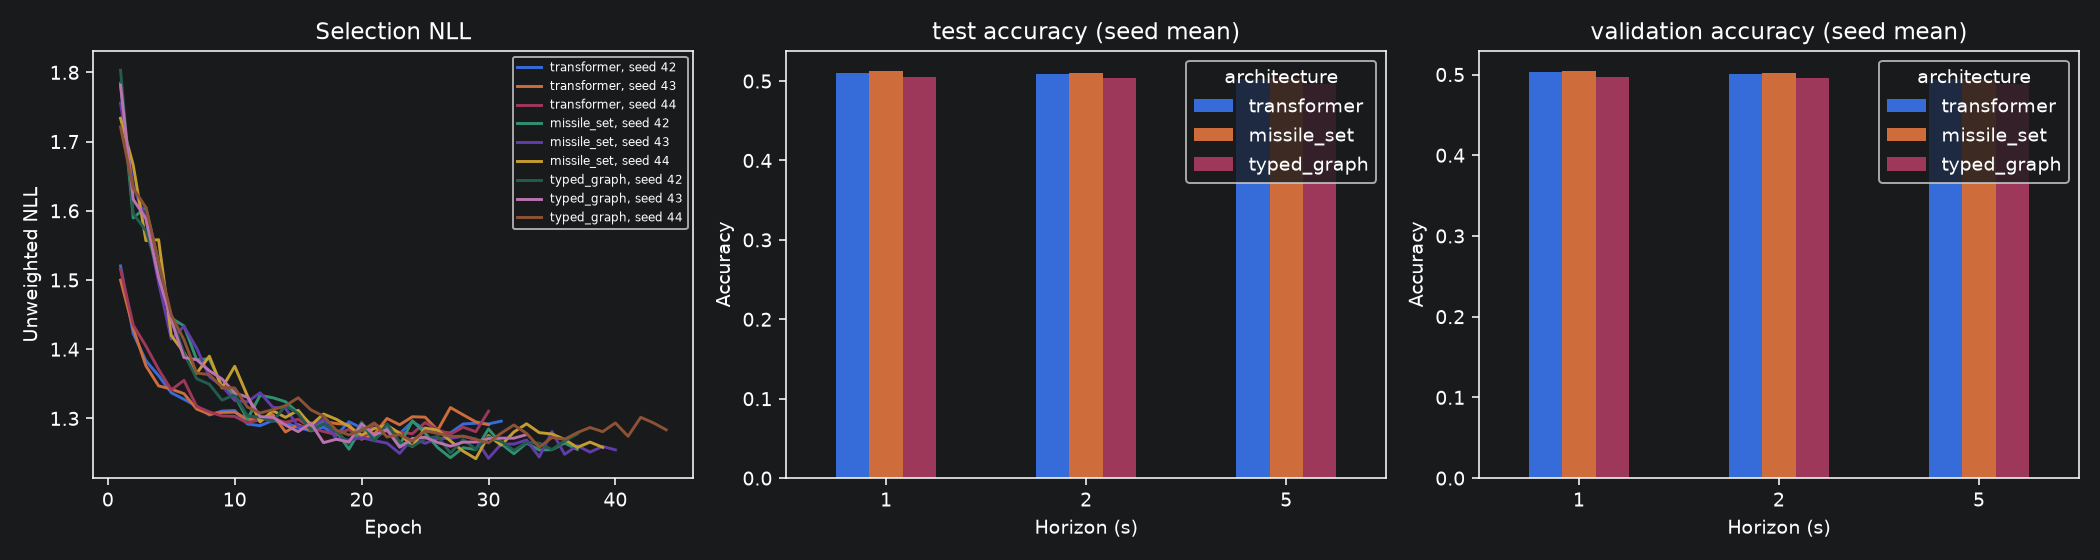

All comparison artifacts: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_enemy_missile_forecasting\comparisons\three_architectures_20261110T102532426770Z
CPU times: total: 15.6 ms
Wall time: 5 ms


In [3]:
%%time
# Display the plots that were actually persisted by the comparison helper.
for path in sorted(OUTPUT.glob("*.png")):
    display(Image(filename=str(path)))
print("All comparison artifacts:", OUTPUT)


## Interpretation

Compare the set encoder with the dense baseline to assess ordering/pooling changes;
compare the graph with the set encoder to assess whether explicit relational
messages add value. Their frame encoders differ in capacity: parameter counts and
training duration are reported, not assumed matched. Class weighting and L1 are
held fixed; summed L1 can still differ with parameter count. NLL and rare-class F1
may move in different directions. Retain unsuccessful seeds and unsupported-class
audits. These experiments forecast recorded catalogue selections; identical executed
controls can have distinct names, so label gains are not automatically physical
maneuver gains. No measured improvement is claimed before training these models.
